# Predict

### Load Model

In [5]:
#using pytorch and keras to set up gpu
import os

# Set Keras backend explicitly to PyTorch and target your MIG GPU
os.environ['PYTORCH_NVML_BASED_CUDA_CHECK'] = '1'
os.environ['CUDA_DEVICE_ORDER'] = 'PCI_BUS_ID'
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
os.environ['KERAS_BACKEND'] = 'torch'

from parameters import *
import numpy as np

# Import load_model directly from keras (not tensorflow.keras)
from keras.models import load_model

In [6]:
#loading tensorflow libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, LeakyReLU
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import os
import numpy as np
import pandas as pd

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from keras_tuner import HyperModel, RandomSearch
from tensorflow.keras.models import load_model

# Disable some console warnings
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [7]:
#validating GPUs with tf
from tensorflow.python.client import device_lib
print("GPUs Available:", tf.config.list_physical_devices('GPU'))

GPUs Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
#validating GPUs with torch
import keras
import torch
print("--- Environment Validation ---")
print(f"Active Keras Backend: {keras.backend.backend()}")
print(f"PyTorch CUDA Available: {torch.cuda.is_available()}")

print("\n--- Hardware Validation ---")
if torch.cuda.is_available():
    print(f"Device Count: {torch.cuda.device_count()}")
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
    
    # 2. Force a micro-computation to ensure libraries aren't just visible, but working
    try:
        print("\nAttempting to push a tensor to the GPU...")
        test_tensor = torch.tensor([1.0, 2.0, 3.0]).cuda()
        test_result = test_tensor * 2
        print(f"Result on GPU: {test_result}")
        print("✅ SUCCESS: The GPU is fully operational and ready for training!")
    except Exception as e:
        print(f"❌ FAILED during computation. Error: {e}")
else:
    print("❌ FAILED: PyTorch cannot see the GPU.")

--- Environment Validation ---
Active Keras Backend: torch
PyTorch CUDA Available: True

--- Hardware Validation ---
Device Count: 1
Device Name: NVIDIA A100 80GB PCIe MIG 4g.40gb

Attempting to push a tensor to the GPU...
Result on GPU: tensor([2., 4., 6.], device='cuda:0')
✅ SUCCESS: The GPU is fully operational and ready for training!


In [9]:
if KERAS_TUNER: 
    best_model_file = 'model_sur/best_keras_model.keras'
else:
    # Define shape based on parameters file neurons
    model_shape = 'mlp_602_'
    model_shape += '_'.join(str(l) for l in NEURONS_PER_LAYER)
    model_shape += '_10'

    best_model_file = 'model_sur/{}_best_model.keras'.format(model_shape)
                                                       

In [10]:
print(best_model_file)
#import os
#os.environ['CUDA_VISIBLE_DEVICES'] = '-1'  # Blinds TensorFlow to any broken GPU paths
#import tensorflow as tf

model_sur/best_keras_model.keras


In [11]:
# Load the best model that we have saved from previous script
model = load_model(best_model_file)

/home/oliviag/.conda/envs/spice_env/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 17 variables whereas the saved optimizer has 1 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


## Process Measurements

### Load data

In [12]:
import csv
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [13]:
#filename = 'test_measurements/rvtnMeasurementData.csv'
#filename = '/home/oliviag/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'
#df = pd.read_csv(filename)
#dataId = df.iloc[:, 2].to_numpy()
#dataVg = df.iloc[:, 0].to_numpy()  

raw_params = {
    'vth0_nom': 1.28751,  
    'vsat_nom': 1.75772,  
    'rdsw_nom':  0.967479,  
    'u0_nom': 1.71788,  
    'nfactor_nom': 32.1932,  
    'eta0_nom': 1.40301 ,  
    'delta_nom': 5.33214,  
}
param_order = [
    'vth0_nom',
    'vsat_nom',
    'rdsw_nom',
    'u0_nom',
    'nfactor_nom',
    'eta0_nom',
    'delta_nom',
]
x_input_raw = np.array([[raw_params[p] for p in param_order]])


In [14]:
# Load test data for comparison
y_test = np.asarray(np.load('{}/npy/x_{}_test_augmented.npy'.format(DATA_DIR, PARAM), allow_pickle=True))
# Load test data for comparison
X_test = np.asarray(np.load('{}/npy/y_{}_test_augmented.npy'.format(DATA_DIR, PARAM), allow_pickle=True))
print(f"Loaded X_test shape (Params): {X_test.shape}") 
print(f"Loaded Y_test shape (IV Curves): {y_test.shape}")
#print("  Col 0:", y_test[0, 0])
#print("  Col 1:", y_test[0, 1])
#print("  Col 2:", y_test[0, 2])

Loaded X_test shape (Params): (10781, 7)
Loaded Y_test shape (IV Curves): (10781, 3)


In [15]:
print(X_test)

[[0.05402498 0.96131346 0.36993976 ... 0.40750882 0.24778849 0.54218151]
 [0.85195104 0.77596834 0.60632439 ... 0.64589912 0.53757379 0.15406345]
 [0.61589093 0.3462886  0.30610191 ... 0.85040743 0.48940559 0.76468679]
 ...
 [0.44629029 0.58023032 0.05639568 ... 0.21543174 0.88698985 0.73854749]
 [0.69001375 0.75111582 0.66576452 ... 0.36251341 0.69002954 0.78423501]
 [0.13158034 0.65445421 0.32930525 ... 0.12077283 0.06377711 0.69518772]]


### Transform Data

Here we will set everything below the noise floor to 0, and log scale just like what was done for training data

In [16]:
'''#look at test data prediction
testIndex=2002
print(X_test[testIndex][2])
dataId = np.asarray(X_test[testIndex][2])'''

'#look at test data prediction\ntestIndex=2002\nprint(X_test[testIndex][2])\ndataId = np.asarray(X_test[testIndex][2])'

In [17]:
# Set values below measurement noise floor to global_min, So we prepare the model for the input measurement data
'''if MYSTIC_MC:
    noiseFloor = -1e-10 #rvtnfets
    
    # find minimum value for data we want to measure and set that to minimum so it doesnt learn any misleading information
    #filename = 'test_measurements/rvtnMeasurementData.csv'
    filename = '/home/oliviag/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'

    df = pd.read_csv(filename)
    dataId_meas = df.iloc[:, 2].to_numpy()
    
    dataId_meas = np.where(dataId_meas < noiseFloor, 0, dataId_meas)
    valid_values = dataId_meas[dataId_meas != 0]
    global_min = np.min(valid_values)
 
    dataId = np.where(dataId < noiseFloor, global_min, dataId)
else:
    noiseFloor = 1e-10 #rvtnfets
    
    # find minimum value for data we want to measure and set that to minimum so it doesnt learn any misleading information
    #filename = 'test_measurements/rvtnMeasurementData.csv'
    filename = '/home/oliviag/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'

    #df = pd.read_csv(filename)
    #dataId_meas = df.iloc[:, 2].to_numpy()
    df = pd.read_csv(filename)
    dataId_meas = df.iloc[:, 2].to_numpy()

# 1. Clean up any extreme drops or negative leakage artifacts by clamping directly to your floor
    dataId_meas = np.where(dataId_meas < noiseFloor, noiseFloor, dataId_meas)

# 2. Extract valid values above the floor to calculate metrics if needed
    valid_values = dataId_meas[dataId_meas > noiseFloor]
    if len(valid_values) > 0:
        global_min = np.min(valid_values)
    else:
        global_min = noiseFloor
    
    #dataId_meas = np.where(dataId_meas < noiseFloor, 0, dataId_meas)
    #valid_values = dataId_meas[dataId_meas != 0]
    #global_min = np.min(valid_values)
 
    dataId = np.where(dataId < noiseFloor, global_min, dataId)'''

"if MYSTIC_MC:\n    noiseFloor = -1e-10 #rvtnfets\n    \n    # find minimum value for data we want to measure and set that to minimum so it doesnt learn any misleading information\n    #filename = 'test_measurements/rvtnMeasurementData.csv'\n    filename = '/home/oliviag/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'\n\n    df = pd.read_csv(filename)\n    dataId_meas = df.iloc[:, 2].to_numpy()\n    \n    dataId_meas = np.where(dataId_meas < noiseFloor, 0, dataId_meas)\n    valid_values = dataId_meas[dataId_meas != 0]\n    global_min = np.min(valid_values)\n \n    dataId = np.where(dataId < noiseFloor, global_min, dataId)\nelse:\n    noiseFloor = 1e-10 #rvtnfets\n    \n    # find minimum value for data we want to measure and set that to minimum so it doesnt learn any misleading information\n    #filename = 'test_measurements/rvtnMeasurementData.csv'\n    filename = '/home/oliviag/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wi

In [18]:
# Set values below measurement noise floor to prevent log10(<=0) errors or training artifacts
import pandas as pd


# ---------------------------------------------------------
# 1. SETUP NOISE FLOOR & REFERENCE CSV DATA
# ---------------------------------------------------------
noiseFloor = 1e-7  # Current noise floor in Amps for cryogenic / room temp NMOS

filename = '/home/oliviag/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'
df = pd.read_csv(filename)

dataVg_meas = df.iloc[:, 1].to_numpy()
dataVd_meas = df.iloc[:, 0].to_numpy()
dataId_meas = df.iloc[:, 2].to_numpy()

# Clean reference measurement curve (clamp below noise floor)
dataId_meas_clean = np.where(dataId_meas < noiseFloor, noiseFloor, dataId_meas)

# Calculate global minimum from valid measured points above noise floor
valid_meas = dataId_meas_clean[dataId_meas_clean > noiseFloor]
global_min = np.min(valid_meas) if len(valid_meas) > 0 else noiseFloor


# ---------------------------------------------------------
# 2. EXTRACT & CLAMP LINEAR TEST TARGETS (Y_test)
# ---------------------------------------------------------
# Extract raw linear current lists from loaded Y_test object array
Y_test_lin_raw = [row[2] for row in y_test]

# Apply noise floor clamping to linear values
Y_test_lin_clean = []
for curve in Y_test_lin_raw:
  arr = np.asarray(curve, dtype=np.float64)
  clamped_arr = np.where(arr < noiseFloor, noiseFloor, arr)
  Y_test_lin_clean.append(clamped_arr.tolist())

print(f"Noise floor ({noiseFloor:.1e} A) applied to Y_test target curves.")
print(f"Global min valid target current: {global_min:12.6e} A")


# ---------------------------------------------------------
# 3. GENERATE Y_test_log FROM CLAMPED LINEAR VALUES
# ---------------------------------------------------------
Y_test_log = []
for i in range(len(y_test)):
  # Take log10 of the noise-floor-clamped linear current
  log_curve = np.log10(Y_test_lin_clean[i]).tolist()

  # Match original 3-column object structure: [Vg, Vd, log10(Id)]
  Y_test_log.append([y_test[i][0], y_test[i][1], log_curve])


# ---------------------------------------------------------
# 4. CONCATENATE LINEAR + LOG (BUILD lin_log_Y_test)
# ---------------------------------------------------------
lin_log_Y_test = []

for i in range(len(y_test)):
  # Use list slicing [:] to avoid in-place mutation bugs!
  lin_pts = list(Y_test_lin_clean[i])
  log_pts = list(Y_test_log[i][2])

  # Concatenate linear (185) + log (185) = 370 total points
  combined_vector = lin_pts + log_pts
  lin_log_Y_test.append(np.asarray(combined_vector, dtype=np.float64))

lin_log_Y_test_matrix = np.array(lin_log_Y_test)

print("================ DATASET PREPARATION COMPLETE ================")
print(f"Total Test Samples          : {len(lin_log_Y_test_matrix)}")
print(
    f"Target Vector Shape (Y_test): {lin_log_Y_test_matrix.shape}"
)  # Expected: (2000, 370)

Noise floor (1.0e-07 A) applied to Y_test target curves.
Global min valid target current: 3.000000e-07 A
================ DATASET PREPARATION COMPLETE ================
Total Test Samples          : 10781
Target Vector Shape (Y_test): (10781, 370)


In [19]:
print(dataVg_meas)
print(dataVd_meas)

[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13
 0.14 0.15 0.16 0.17 0.18 0.19 0.2  0.21 0.22 0.23 0.24 0.25 0.26 0.27
 0.28 0.29 0.3  0.31 0.32 0.33 0.34 0.35 0.36 0.37 0.38 0.39 0.4  0.41
 0.42 0.43 0.44 0.45 0.46 0.47 0.48 0.49 0.5  0.51 0.52 0.53 0.54 0.55
 0.56 0.57 0.58 0.59 0.6  0.61 0.62 0.63 0.64 0.65 0.66 0.67 0.68 0.69
 0.7  0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.8  0.81 0.82 0.83
 0.84 0.85 0.86 0.87 0.88 0.89 0.9  0.91 0.92 0.93 0.94 0.95 0.96 0.97
 0.98 0.99 1.   1.01 1.02 1.03 1.04 1.05 1.06 1.07 1.08 1.09 1.1  1.11
 1.12 1.13 1.14 1.15 1.16 1.17 1.18 1.19 1.2  1.21 1.22 1.23 1.24 1.25
 1.26 1.27 1.28 1.29 1.3  1.31 1.32 1.33 1.34 1.35 1.36 1.37 1.38 1.39
 1.4  1.41 1.42 1.43 1.44 1.45 1.46 1.47 1.48 1.49 1.5  1.51 1.52 1.53
 1.54 1.55 1.56 1.57 1.58 1.59 1.6  1.61 1.62 1.63 1.64 1.65 1.66 1.67
 1.68 1.69 1.7  1.71 1.72 1.73 1.74 1.75 1.76 1.77 1.78 1.79 1.8  1.81
 1.82 1.83 1.84 1.85]
[1.48 1.48 1.48 1.48 1.48 1.48 1.48 1.48 1.48 1.48 1.48

### Scale Data

In [20]:
# Need to import scaling function, open terminal--> pip install import_ipynb
import import_ipynb
from ml_custom_scaler import Scaler

In [21]:
scaler = Scaler()

In [22]:
# Grab scaling Values we used for all of the training data

filename = 'scaling_boundaries.txt'
with open(filename, 'r') as file:
        boundaries = {}
        
        for line in file:
            key_value = line.strip().split(': ')
            if len(key_value) == 2:
                key = key_value[0] 
                value = float(key_value[1]) 
                boundaries[key] = value 

min_lin = boundaries['min_lin']
max_lin = boundaries['max_lin']
min_log = boundaries['min_log']
#min_log = np.log(1e-10)
max_log = boundaries['max_log']

print("Min Linear:", min_lin)
print("Max Linear:", max_lin)
print("Min Log:", min_log)
print("Max Log:", max_log)

Min Linear: 1e-07
Max Linear: 0.00630188946
Min Log: -16.11809565095832
Max Log: -5.066905776264235


In [23]:


# -----------------------------------------------------------------
# 1. SPLIT MATRIX
# -----------------------------------------------------------------
y_true_lin_raw = lin_log_Y_test_matrix[:, :185]
y_true_log_raw = lin_log_Y_test_matrix[:, 185:]

# -----------------------------------------------------------------
# 2. CONVERT UNITS AND SCALE SEPARATELY (FIXED)
# -----------------------------------------------------------------
# Define proper linear bounds (Linear current cannot be negative, starts at 0.0)
min_lin_val = 0.0
max_lin_val = max_lin  # 0.0014708 A

# Process Linear Head
if np.max(y_true_lin_raw) > 0.1:
  y_true_lin_amps = y_true_lin_raw * max_lin_val  # Rescale to [0, max_lin]
else:
  y_true_lin_amps = y_true_lin_raw

# Scale Linear head strictly using Linear bounds
y_true_lin_scaled = (y_true_lin_amps - min_lin_val) / (
    max_lin_val - min_lin_val
)
y_true_lin_scaled = np.clip(y_true_lin_scaled, 0.0, 1.0)

# Process Log Head (Using Natural Log boundaries: min_log and max_log)
y_true_log_natural = np.log(np.maximum(y_true_lin_amps, 1e-20))

# Scale Log head strictly using Log bounds
y_true_log_scaled = (y_true_log_natural - min_log) / (max_log - min_log)
y_true_log_scaled = np.clip(y_true_log_scaled, 0.0, 1.0)

# -----------------------------------------------------------------
# 3. COMBINE INTO FULL SCALED MATRIX
# -----------------------------------------------------------------
y_true_scaled = np.hstack([y_true_lin_scaled, y_true_log_scaled])

# -----------------------------------------------------------------
# 4. SANITY CHECKS
# -----------------------------------------------------------------
print("=== SCALED GROUND TRUTH SANITY CHECK (FIXED) ===")
print("Shape of y_true_scaled :", y_true_scaled.shape)
print(f"Min (Target: 0.0)      : {np.min(y_true_scaled):.4f}")
print(f"Max (Target: 1.0)      : {np.max(y_true_scaled):.4f}")
print("=== GROUND TRUTH Y (LOADED FROM NPY) ===")
print("Shape of lin_log_Y_test_matrix:", lin_log_Y_test_matrix.shape)
print(f"Min value : {np.min(lin_log_Y_test_matrix):.4f}")
print(f"Max value : {np.max(lin_log_Y_test_matrix):.4f}")

=== SCALED GROUND TRUTH SANITY CHECK (FIXED) ===
Shape of y_true_scaled : (10781, 370)
Min (Target: 0.0)      : 0.0000
Max (Target: 1.0)      : 0.9887
=== GROUND TRUTH Y (LOADED FROM NPY) ===
Shape of lin_log_Y_test_matrix: (10781, 370)
Min value : -7.0000
Max value : 0.8823


In [24]:
'''# -----------------------------------------------------------------
# 0. WHAT IS ACTUALLY IN THE FILE -- run this first, once
# -----------------------------------------------------------------
y_true_lin_raw = lin_log_Y_test_matrix[:, :185]
y_true_log_raw = lin_log_Y_test_matrix[:, 185:]
print("lin half:", y_true_lin_raw.min(), y_true_lin_raw.max())
print("log half:", y_true_log_raw.min(), y_true_log_raw.max())

# -----------------------------------------------------------------
# 1. SINGLE SOURCE OF TRUTH FOR THE LOG TRANSFORM
# -----------------------------------------------------------------
LOG_BASE  = 10                      # <-- set from the print above
LOG_FLOOR = 1e-14                   # below ngspice's ~1.48e-12 noise floor

to_log   = (lambda x: np.log10(np.clip(x, LOG_FLOOR, None))) if LOG_BASE == 10 \
           else (lambda x: np.log(np.clip(x, LOG_FLOOR, None)))
from_log = (lambda x: 10.0 ** x) if LOG_BASE == 10 else np.exp

# -----------------------------------------------------------------
# 2. AMPS COME FROM THE LOG HALF -- it preserves the small currents
# -----------------------------------------------------------------
y_true_log_raw = lin_log_Y_test_matrix[:, 185:]
y_true_lin_amps = from_log(y_true_log_raw)          # (N, 185), strictly positive

# -----------------------------------------------------------------
# 3. SCALE BOTH HEADS FROM CONSTANTS DERIVED FROM THIS DATA
# -----------------------------------------------------------------
min_log, max_log = y_true_log_raw.min(), y_true_log_raw.max()
min_lin, max_lin = 0.0, y_true_lin_amps.max()

y_true_log_scaled = np.clip((y_true_log_raw - min_log) / (max_log - min_log), 0.0, 1.0)
y_true_lin_scaled = np.clip((y_true_lin_amps - min_lin) / (max_lin - min_lin), 0.0, 1.0)

y_true_scaled = np.hstack([y_true_lin_scaled, y_true_log_scaled])

# -----------------------------------------------------------------
# 4. CHECKS
# -----------------------------------------------------------------
print("scaled:", y_true_scaled.shape, y_true_scaled.min(), y_true_scaled.max())
print("amps  :", f"{y_true_lin_amps.min():.3e} .. {y_true_lin_amps.max():.3e}")
assert (y_true_lin_amps > 0).all(), "negative current -- from_log base is wrong"'''



'# -----------------------------------------------------------------\n# 0. WHAT IS ACTUALLY IN THE FILE -- run this first, once\n# -----------------------------------------------------------------\ny_true_lin_raw = lin_log_Y_test_matrix[:, :185]\ny_true_log_raw = lin_log_Y_test_matrix[:, 185:]\nprint("lin half:", y_true_lin_raw.min(), y_true_lin_raw.max())\nprint("log half:", y_true_log_raw.min(), y_true_log_raw.max())\n\n# -----------------------------------------------------------------\n# 1. SINGLE SOURCE OF TRUTH FOR THE LOG TRANSFORM\n# -----------------------------------------------------------------\nLOG_BASE  = 10                      # <-- set from the print above\nLOG_FLOOR = 1e-14                   # below ngspice\'s ~1.48e-12 noise floor\n\nto_log   = (lambda x: np.log10(np.clip(x, LOG_FLOOR, None))) if LOG_BASE == 10            else (lambda x: np.log(np.clip(x, LOG_FLOOR, None)))\nfrom_log = (lambda x: 10.0 ** x) if LOG_BASE == 10 else np.exp\n\n# -------------------------

## Predict

In [25]:
X_input = X_test[:1]

print("Input shape to model:", X_input.shape)  # Should be (1, 7)

# ---------------------------------------------------------
# 2. RUN FORWARD MODEL PREDICTION
# ---------------------------------------------------------
# Predictions shape will be (1, 370) -> 185 linear points + 185 log points
predictions_scaled = model.predict(X_input)

# ---------------------------------------------------------
# 3. UNSCALE OUTPUT CURVES BACK TO PHYSICAL UNITS (AMPS)
# ---------------------------------------------------------
N_points = 185

# Slice prediction into Linear head (first 185) and Log head (last 185)
y_pred_lin_scaled = predictions_scaled[:, :N_points]
y_pred_log_scaled = predictions_scaled[:, N_points:]

# Unscale Linear head to physical Amperes
y_pred_lin_amps = y_pred_lin_scaled * (max_lin - min_lin) + min_lin

# Unscale Log head to Natural Log, then exponentiate to physical Amperes
y_pred_log_natural = y_pred_log_scaled * (max_log - min_log) + min_log
y_pred_log_amps = np.exp(y_pred_log_natural)

# ---------------------------------------------------------
# 4. PRINT PREDICTION SUMMARY
# ---------------------------------------------------------
print("\n================ FORWARD PREDICTION RESULT ================")
print(
    f"Linear Head Current Range : {np.min(y_pred_lin_amps[0]):.3e} A  to  {np.max(y_pred_lin_amps[0]):.3e} A"
)
print(
    f"Log Head Current Range    : {np.min(y_pred_log_amps[0]):.3e} A  to  {np.max(y_pred_log_amps[0]):.3e} A"
)

# Optional: Print the first 5 predicted current values along the curve
print("\nFirst 5 predicted linear current points (Amps):")
for idx, val in enumerate(y_pred_lin_amps[0][:5]):
  print(f"  Point #{idx+1}: {val:.6e} A")

Input shape to model: (1, 7)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step

================ FORWARD PREDICTION RESULT ================
Linear Head Current Range : -7.838e-06 A  to  2.662e-03 A
Log Head Current Range    : 8.136e-08 A  to  2.987e-03 A

First 5 predicted linear current points (Amps):
  Point #1: -1.868436e-06 A
  Point #2: -1.809957e-06 A
  Point #3: -6.685646e-06 A
  Point #4: 6.292685e-07 A
  Point #5: -4.584987e-06 A


In [26]:
'''min_lin_n, max_lin_n = 1e-07, 0.8823391919538994
X_input = X_test[:1]
print("Input shape to model:", X_input.shape)      # (1, 7)

predictions_scaled = model.predict(X_input)         # (1, 370)

N_points = 185
y_pred_lin_scaled = predictions_scaled[:, :N_points]
y_pred_log_scaled = predictions_scaled[:, N_points:]

# Linear head: unscale to normalized, then to amps
y_pred_lin_amps = (y_pred_lin_scaled * (max_lin_n - min_lin_n) + min_lin_n) * max_lin

# Log head: unscale to log10(normalized), exponentiate, then to amps
y_pred_log_norm = y_pred_log_scaled * (max_log - min_log) + min_log   # -7.0 .. -0.054
y_pred_log_amps = (10.0 ** y_pred_log_norm) * max_lin

print("\n================ FORWARD PREDICTION RESULT ================")
print(f"Linear Head : {y_pred_lin_amps[0].min():.3e} A  to  {y_pred_lin_amps[0].max():.3e} A")
print(f"Log Head    : {y_pred_log_amps[0].min():.3e} A  to  {y_pred_log_amps[0].max():.3e} A")

print("\nFirst 5 predicted currents from the LOG head (Amps):")
for idx, val in enumerate(y_pred_log_amps[0][:5]):
    print(f"  Point #{idx+1}: {val:.6e} A")'''


'min_lin_n, max_lin_n = 1e-07, 0.8823391919538994\nX_input = X_test[:1]\nprint("Input shape to model:", X_input.shape)      # (1, 7)\n\npredictions_scaled = model.predict(X_input)         # (1, 370)\n\nN_points = 185\ny_pred_lin_scaled = predictions_scaled[:, :N_points]\ny_pred_log_scaled = predictions_scaled[:, N_points:]\n\n# Linear head: unscale to normalized, then to amps\ny_pred_lin_amps = (y_pred_lin_scaled * (max_lin_n - min_lin_n) + min_lin_n) * max_lin\n\n# Log head: unscale to log10(normalized), exponentiate, then to amps\ny_pred_log_norm = y_pred_log_scaled * (max_log - min_log) + min_log   # -7.0 .. -0.054\ny_pred_log_amps = (10.0 ** y_pred_log_norm) * max_lin\n\nprint("\n================ FORWARD PREDICTION RESULT ================")\nprint(f"Linear Head : {y_pred_lin_amps[0].min():.3e} A  to  {y_pred_lin_amps[0].max():.3e} A")\nprint(f"Log Head    : {y_pred_log_amps[0].min():.3e} A  to  {y_pred_log_amps[0].max():.3e} A")\n\nprint("\nFirst 5 predicted currents from the LOG h

In [27]:
import joblib

# Load X scaler to inspect real physical input parameters
scaler_x = joblib.load('scalers/scaler_x.save')
X_input_phys = scaler_x.inverse_transform(X_input)

params = [
    'vth0_nom',
    'vsat_nom',
    'rdsw_nom',
    'u0_nom',
    'nfactor_nom',
    'eta0_nom',
    'delta_nom',
]

print("\n--- INPUT SPICE PARAMETERS FOR THIS SAMPLE ---")
for i, name in enumerate(params):
  print(
    f"{name:>12}: {X_input_phys[0][i]:12.6e}  (Scaled: {X_input[0][i]:.4f})"
  )

FileNotFoundError: [Errno 2] No such file or directory: 'scalers/scaler_x.save'

In [ ]:
y_pred_scaled = model.predict(X_test, verbose=1)  # Shape: (2000, 370)

# 2. Slice predictions
y_pred_lin_scaled = y_pred_scaled[:, :185]
y_pred_log_scaled = y_pred_scaled[:, 185:]

# 3. Unscale Linear Head -> Amperes (A)
y_pred_lin_amps = y_pred_lin_scaled * (max_lin - min_lin) + min_lin

# 4. Unscale Log Head -> Natural Log -> Amperes (A)
y_pred_log_natural = y_pred_log_scaled * (max_log - min_log) + min_log
y_pred_log_amps = np.exp(y_pred_log_natural)

print("\n=== UNSCALED PREDICTIONS SUMMARY ===")
print(
    f"Predicted Linear Current Range : [{np.min(y_pred_lin_amps):.3e} A, {np.max(y_pred_lin_amps):.3e} A]"
)
print(
    f"Predicted Log-head Current Range: [{np.min(y_pred_log_amps):.3e} A, {np.max(y_pred_log_amps):.3e} A]"
)
print(min_log, max_log)
'''MIN_LIN_N, MAX_LIN_N = 1e-07, 0.8823391919538994   # normalized bounds from the .npy
AMPS_PER_NORM = 0.0014708                           # normalized -> amps

y_pred_scaled = model.predict(X_test, verbose=1)     # (N, 370)

y_pred_lin_scaled = y_pred_scaled[:, :185]
y_pred_log_scaled = y_pred_scaled[:, 185:]

# Linear head -> normalized -> amps
y_pred_lin_amps = (y_pred_lin_scaled * (MAX_LIN_N - MIN_LIN_N) + MIN_LIN_N) * AMPS_PER_NORM

# Log head -> log10(normalized) -> normalized -> amps
y_pred_log_norm = y_pred_log_scaled * (max_log - min_log) + min_log    # -7.0 .. -0.054
y_pred_log_amps = (10.0 ** y_pred_log_norm) * AMPS_PER_NORM

print("\n=== UNSCALED PREDICTIONS SUMMARY ===")
print(f"Linear head : [{y_pred_lin_amps.min():.3e} A, {y_pred_lin_amps.max():.3e} A]")
print(f"Log head    : [{y_pred_log_amps.min():.3e} A, {y_pred_log_amps.max():.3e} A]")
print("min_log, max_log:", min_log, max_log)
true_amps = (10.0 ** (lin_log_Y_test_matrix[:, 185:])) * AMPS_PER_NORM

err = np.abs(np.log10(y_pred_log_amps) - np.log10(true_amps))
print(f"median |error|: {np.median(err):.4f} decades")
print(f"90th pct      : {np.percentile(err, 90):.4f} decades")
print(f"worst         : {err.max():.4f} decades")'''


### Plot Simulation Using Predictions

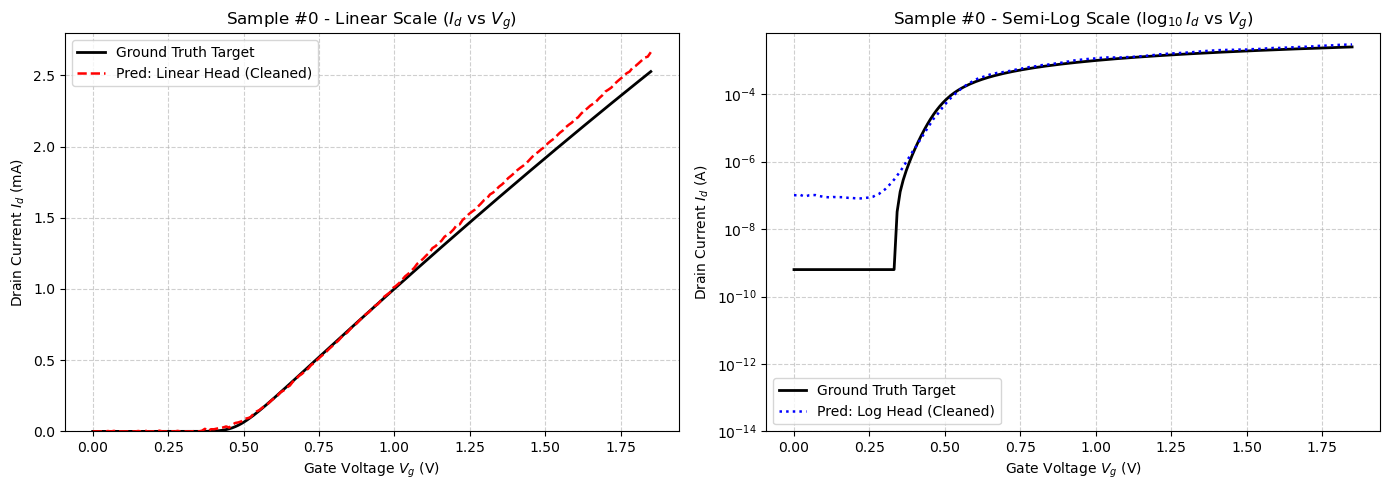

In [28]:
import matplotlib.pyplot as plt
import numpy as np



NOISE_THRESHOLD = 1e-14

sample_idx = 0  # Sample index to display

# Ground Truth for sample_idx
y_true_raw = y_true_lin_amps[sample_idx]

# Linear Head Predictions for sample_idx
y_pred_lin_raw = y_pred_lin_amps[sample_idx]

# Log Head Predictions for sample_idx
y_pred_log_raw = y_pred_log_amps[sample_idx]

# Zero out values at or below NOISE_THRESHOLD for Linear display
y_true_clean = np.where(y_true_raw <= NOISE_THRESHOLD, 0.0, y_true_raw)
#y_true_clean = y_true_raw
y_pred_lin_clean = np.where(
    y_pred_lin_raw <= NOISE_THRESHOLD, 0.0, y_pred_lin_raw
)
y_pred_log_clean = np.where(
    y_pred_log_raw <= NOISE_THRESHOLD, 0.0, y_pred_log_raw
)

# Convert 0.0 to NaN for Semi-Log display (prevents log(0) errors)
y_true_log_plot = np.where(y_true_clean == 0.0, np.nan, y_true_clean)
y_pred_lin_log_plot = np.where(y_pred_lin_clean == 0.0, np.nan, y_pred_lin_clean)
y_pred_log_log_plot = np.where(y_pred_log_clean == 0.0, np.nan, y_pred_log_clean)

# Gate Voltage sweep array
if 'dataVg_meas' in locals() and len(dataVg_meas) == N_points:
  vg = dataVg_meas
else:
  vg = np.linspace(0.0, 1.85, N_points)


# ---------------------------------------------------------
# 2. PLOT COMPARISON (LINEAR & LOG SCALES)
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Left Plot: Linear Scale (Id vs Vg) ---
ax1.plot(vg, y_true_clean * 1e3, 'k-', linewidth=2, label='Ground Truth Target')
ax1.plot(
    vg,
    y_pred_lin_clean * 1e3,
    'r--',
    linewidth=1.8,
    label='Pred: Linear Head (Cleaned)',
)
#ax1.plot(vg, y_true_clean * 1e3, 'k-', linewidth=2, label='Ground Truth')
#ax1.plot(vg, y_pred_log_clean * 1e3, 'r--', linewidth=1.8, label='Pred (log head)')



ax1.set_title(f'Sample #{sample_idx} - Linear Scale ($I_d$ vs $V_g$)')
ax1.set_xlabel('Gate Voltage $V_g$ (V)')
ax1.set_ylabel('Drain Current $I_d$ (mA)')
ax1.set_ylim(bottom=0.0)  # Enforce bottom boundary at 0
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()


# --- Right Plot: Semi-Log Scale (log10(Id) vs Vg) ---
ax2.semilogy(
    vg, y_true_log_plot, 'k-', linewidth=2, label='Ground Truth Target'
)

ax2.semilogy(
    vg,
    y_pred_log_log_plot,
    'b:',
    linewidth=1.8,
    label='Pred: Log Head (Cleaned)',
)

# Set lower limit right at the noise floor cutoff
ax2.set_ylim(bottom=NOISE_THRESHOLD)
ax2.set_title(
    f'Sample #{sample_idx} - Semi-Log Scale ($\log_{{10}} I_d$ vs $V_g$)'
)
ax2.set_xlabel('Gate Voltage $V_g$ (V)')
ax2.set_ylabel('Drain Current $I_d$ (A)')
ax2.grid(True, which='both', linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

In [44]:
#print(vg)

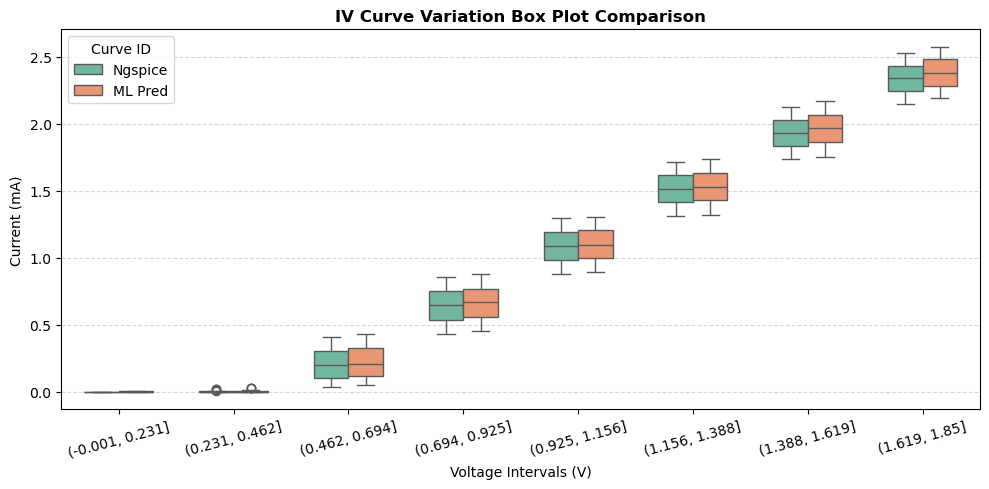

In [43]:

import seaborn as sns
plt.close()

# 1. Your exact DataFrame setup
df = pd.DataFrame(
    {"Voltage (V)": vg, "Ngspice": y_true_clean * 1e3, "ML Pred": y_pred_lin_clean * 1e3}
)

# CRITICAL FIX: Convert continuous voltage into 8 distinct categorical bins
# Change bins=8 to whatever number of intervals fits your voltage sweep span best
#df["Voltage Bin"] = pd.cut(df["Voltage (V)"], bins=8)
df["Voltage Bin"] = pd.qcut(df["Voltage (V)"], q=8, duplicates="drop")

# 2. Melt using your structural columns, swapping the raw voltage for the categorical bins
df_melted = df.melt(
    id_vars=["Voltage Bin"],
    value_vars=["Ngspice", "ML Pred"],
    var_name="Curve ID",
    value_name="Current (A)",
)

# 3. Create the box plot using the newly created bins on the X-axis
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_melted,
    x="Voltage Bin",
    y="Current (A)",
    hue="Curve ID",
    palette="Set2",
    width=0.6,
)

# Clean up label formatting so they don't look cluttered
plt.xticks(rotation=15)
plt.xlabel("Voltage Intervals (V)")
plt.ylabel("Current (mA)")
plt.title("IV Curve Variation Box Plot Comparison", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



BSIMIMG not supported in ngspice. For now, plug values into PDK and simulate in HSPICE. Copy back Id values to test_measurements/testPredictionValues

brew info ngspice --> Look at output of this command and install needed dependencies

brew install ngspice

pip install PySpice

In [24]:
! ngspice -b ngspice_pdk/netlist_eglvt.sp

/bin/bash: line 1: ngspice: command not found


In [25]:
import PySpice
print("PySpice version:", PySpice.__version__)

PySpice version: 1.5


In [25]:
'''from sklearn.decomposition import PCA

# y_train_log = the (N, 185) log-scaled target half you trained on
pca = PCA(n_components=20).fit(y_train_log)
print(pca.explained_variance_ratio_.cumsum()[[4, 9, 14, 19]])
z_train = pca.transform(y_train_log)     # (N, 20)
z_val   = pca.transform(y_val_log)

# model: Input(7) -> ... -> Dense(20)
model.fit(X_train, z_train, validation_data=(X_val, z_val))

# predict and reconstruct
pred_log_scaled = pca.inverse_transform(model.predict(X_test))   # (N, 185)
pred_log_norm   = pred_log_scaled * (max_log - min_log) + min_log
pred_amps       = (10.0 ** pred_log_norm) * AMPS_PER_NORM
recon = pca.inverse_transform(pca.transform(y_test_log))
print("PCA-only reconstruction error:", np.abs(recon - y_test_log).max())
'''


NameError: name 'y_train_log' is not defined